# Deep Learning using Keras: Transfer Learning
Dataset: [Kaggle's Dog Breed Identification](https://www.kaggle.com/competitions/dog-breed-identification)

This file focuses on building an image classification **Convolutional Neural Network (CNN)** with _Keras_ using **transfer learning**, starting from a pre-trained [MobileNetV2](https://www.kaggle.com/models/google/mobilenet-v2) base (which originally sourced from [TensorFlow to explore different models](https://www.tensorflow.org/resources/models-datasets)). The work covers two stages: **feature extraction** (frozen base, new classification head) and **fine-tuning** (unfreezing the top layers of the base at a lower learning rate).


_Disclaimer_: Working with Kaggle dataset requires to accept competition rules on Kaggle website before downloading occurs, using an [Kaggle API token](https://www.kaggle.com/docs/api). Additionally, best worked with _T4 GPU_ settings on Google Colab.

In [ ]:
## 0.0 Installing packages and authenticating with Kaggle
!pip install -q --upgrade kagglehub

import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shutil
import pathlib

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.model_selection import train_test_split


# 0.0.1. Logging in to access Dog Breed Identification Dataset
kagglehub.login() # need active Kaggle API token


# 0.0.2. Setting the SEED for reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)

## 1. Project and Dataset Selection
From Kaggle, we've selected the [Dog Breed Identification](https://www.kaggle.com/competitions/dog-breed-identification) competition dataset. This is a **multi-class image classification** task: we predict a dog's breed (120 classes) from its photo.

The competition provides a labeled `train/` folder of images along with `labels.csv`, which maps each image ID to its breed. The competition's `test/` folder is **unlabeled**, so it can't be used to measure accuracy. We'll use only the labeled training images and split them ourselves into training, validation, and test sets (70%/15%/15% ratio).

In [ ]:
## 1.1. Downloading Dog Breed Identification competition data
data_path = kagglehub.competition_download("dog-breed-identification")
print('Data downloaded to: {}'.format(data_path))

# 1.1.1. Inspecting the folder
data_dir = pathlib.Path(data_path)
image_count = len(list(data_dir.glob('train/*.jpg')))
print('Labeled training images: {}'.format(image_count))

train_path = os.path.join(data_path, 'train')

100%|██████████| 691M/691M [00:04<00:00, 171MB/s]

Extracting files...


Data downloaded to: /root/.cache/kagglehub/competitions/dog-breed-identification
Labeled training images: 10222


In [ ]:
# 1.2. Notes on the Folder Structure of the Dataset
### Downloaded structure from Kaggle (images are NOT sorted by breed):
    # dog-breed-identification/
    #   labels.csv              <- maps each image id to its breed
    #   sample_submission.csv   <- not used
    #   test/                   <- UNLABELED images, not used
    #   train/                  <- 10,222 labeled images, all in one folder


### Required structure for image_dataset_from_directory (PDF p.5, Appendix): one folder per class.
### This will be build in Section 2.1.5 using labels.csv, split into training / validation / test
###   at 70% / 15% / 15% (PDF p.3, Requirement 5):

    # dog_split/
    #   train/
    #       affenpinscher/
    #       beagle/
    #       golden_retriever/
    #       ... (120 breed folders)

    #   validation/
    #       affenpinscher/
    #       beagle/
    #       golden_retriever/
    #       ... (same 120 breed folders)

    #   test/
    #       affenpinscher/
    #       beagle/
    #       golden_retriever/
    #       ... (same 120 breed folders)

# 2. Pre-Processing
In this section, we prepare the model: loading the labels, checking the data for consistency examining the classes, splitting the data into training, validation, and test sets, and loading them with Keras.

In [34]:
## 2.1. Loading and Examining the Data
# 2.1.1. Loading labels into Panda's DataFrame
labels_path = os.path.join(data_path, 'labels.csv')
labels_df = pd.read_csv(labels_path)


# 2.1.2. Number of images and classes
print('Number of images: {}'.format(len(labels_df)))

labels_df.head()

Number of images: 10222


,id,breed
0,000bec180eb18c7604dcecc8fe0dba07,boston_bull
1,001513dfcb2ffafc82cccf4d8bbaba97,dingo
2,001cdf01b096e06d78e9e5112d419397,pekinese
3,00214f311d5d2247d5dfe4fe24b2303d,bluetick
4,0021f9ceb3235effd7fcde7f7538ed62,golden_retriever


In [ ]:
## 2.2. Exaiming data for consistency (checking for NULLs, duplicates, and any missing files)
# 2.2.1. Checking for missing values and duplicate image IDs
print('Missing values per column:')
print(labels_df.isna().sum())
print('Duplicate image IDs: {}'.format(labels_df['id'].duplicated().sum()))

Missing values per column:
id       0
breed    0
dtype: int64
Duplicate image IDs: 0


In [ ]:
## 2.3. Splitting data into training, validation, and test sets
# 2.3.1. Splitting off 70% for training (the other 30% is held out)
train_df, holdout_df = train_test_split(labels_df, test_size = 0.30, random_state = SEED, stratify = labels_df['breed'])

# 2.3.2. Splitting the held-out 30% in half: 15% validation, 15% test
validation_df, test_df = train_test_split(holdout_df, test_size = 0.50, random_state = SEED, stratify = holdout_df['breed'])

# 2.3.3. Confirming the split sizes
print('Training:    {} images ({:.1%})'.format(len(train_df), len(train_df) / len(labels_df)))
print('Validation:  {} images ({:.1%})'.format(len(validation_df), len(validation_df) / len(labels_df)))
print('Test:        {} images ({:.1%})'.format(len(test_df), len(test_df) / len(labels_df)))

Training:    7155 images (70.0%)
Validation:  1533 images (15.0%)
Test:        1534 images (15.0%)


In [ ]:
## 2.4. Building the folder structure (one folder per breed)
split_path = 'dog_split'

# 2.4.1. Copying each image into <split>/<breed>/
def CopyImages(split_df, split_name):
  for index, row in split_df.iterrows():
    breed_folder = os.path.join(split_path, split_name, row['breed'])
    os.makedirs(breed_folder, exist_ok = True)

    source_file = os.path.join(train_path, row['id'] + '.jpg')
    shutil.copy(source_file, breed_folder)

# 2.4.2. Counting breed folders and copied images (within CopyImages)
  split_dir = pathlib.Path(split_path) / split_name
  num_folders = len(list(split_dir.glob('*')))
  num_images = len(list(split_dir.glob('*/*.jpg')))
  print('{}: {} breed folders, {} images'.format(split_name, num_folders, num_images))


CopyImages(train_df, 'train')
CopyImages(validation_df, 'validation')
CopyImages(test_df, 'test')

train: 120 breed folders, 7155 images
validation: 120 breed folders, 1533 images
test: 120 breed folders, 1534 images


In [ ]:
## 2.5. Loading the training, validation, and test sets
BATCH_SIZE = 32
IMG_SIZE = (160, 160)

# 2.5.1. Loading each set from its folder
train_dataset = tf.keras.utils.image_dataset_from_directory(os.path.join(split_path, 'train'),
                                                            shuffle = True,
                                                            seed = SEED,
                                                            batch_size = BATCH_SIZE,
                                                            image_size = IMG_SIZE)

validation_dataset = tf.keras.utils.image_dataset_from_directory(os.path.join(split_path, 'validation'),
                                                                 shuffle = False,
                                                                 batch_size = BATCH_SIZE,
                                                                 image_size = IMG_SIZE)

test_dataset = tf.keras.utils.image_dataset_from_directory(os.path.join(split_path, 'test'),
                                                           shuffle = False,
                                                           batch_size = BATCH_SIZE,
                                                           image_size = IMG_SIZE)

# 2.5.2. Getting the breed names from the folder names
class_names = train_dataset.class_names
print('Number of classes: {}'.format(len(class_names)))
print('First 5 classes: {}'.format(class_names[:5]))

# 2.5.3. Configuring the datasets for performance
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size = AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size = AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size = AUTOTUNE)

Found 7155 files belonging to 120 classes.
Found 1533 files belonging to 120 classes.
Found 1534 files belonging to 120 classes.
Number of classes: 120
First 5 classes: ['affenpinscher', 'afghan_hound', 'african_hunting_dog', 'airedale', 'american_staffordshire_terrier']


## 3. Model Construction: Feature Extraction
In this section, we build the transfer learning model. We start from a pre-trained [MobileNetV2](https://www.kaggle.com/models/google/mobilenet-v2) base from [Keras Applications](https://keras.io/api/applications/), **freeze** it, and train only a new classification head on top (feature extraction).

In [ ]:
## 3.1. Data Augmentation
data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.2),
])

In [ ]:
## 3.2. Creating the base model from the pre-trained MobileNetV2
IMG_SHAPE = IMG_SIZE + (3,)
base_model = MobileNetV2(input_shape = IMG_SHAPE,
                         include_top = False,
                         weights = 'imagenet')

# 3.2.1. Freezing the convolutional base
base_model.trainable = False

print('Number of layers in the base model: {}'.format(len(base_model.layers)))
print('Trainable weights in the base model: {}'.format(len(base_model.trainable_weights)))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Number of layers in the base model: 154
Trainable weights in the base model: 0


In [ ]:
## 3.3. Adding a classification
num_classes = len(class_names)

global_average_layer = layers.GlobalAveragePooling2D()
prediction_layer = layers.Dense(num_classes)

# 3.3.a. Changing the pieces together into one model
inputs = keras.Input(shape = IMG_SHAPE)

x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training = False)
x = global_average_layer(x)
x = layers.Dropout(0.2)(x)

outputs = prediction_layer(x)
model = keras.Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │       153,720 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,411,704 (9.20 MB)

 Trainable params: 153,720 (600.47 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
## 3.4. Compiling the model
base_learning_rate = 0.001
model.compile(optimizer = keras.optimizers.Adam(learning_rate = base_learning_rate),
              loss = keras.losses.SparseCategoricalCrossentropy(from_logits = True),
              metrics = ['accuracy'])

# 3.4.1. Training the model (Experiment #1: Baseline)
initial_epochs = 10
history = model.fit(train_dataset,
                    epochs = initial_epochs,
                    validation_data = validation_dataset)

# 3.4.2. Logging the experiment
experiment_log = []
experiment_log.append({'Exp': 1,
                       'Parameters': 'Base = MobileNetV2, frozen base, LR = 0.001, batch size = 32, '
                                      'epochs = 10, dropout = 0.2, with augmentation',
                       'Train Acc.': history.history['accuracy'][-1],
                       'Validation Acc.': history.history['val_accuracy'][-1]})
pd.DataFrame(experiment_log)

Epoch 1/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 23s 59ms/step - accuracy: 0.3290 - loss: 2.8709 - val_accuracy: 0.6928 - val_loss: 1.1785
Epoch 2/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 14s 62ms/step - accuracy: 0.5720 - loss: 1.5718 - val_accuracy: 0.7299 - val_loss: 0.9562
Epoch 3/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 12s 54ms/step - accuracy: 0.6299 - loss: 1.3041 - val_accuracy: 0.7423 - val_loss: 0.8652
Epoch 4/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 20s 50ms/step - accuracy: 0.6653 - loss: 1.1754 - val_accuracy: 0.7378 - val_loss: 0.8607
Epoch 5/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 12s 51ms/step - accuracy: 0.6974 - loss: 1.0517 - val_accuracy: 0.7456 - val_loss: 0.8466
Epoch 6/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 12s 52ms/step - accuracy: 0.7168 - loss: 0.9728 - val_accuracy: 0.7397 - val_loss: 0.8547
Epoch 7/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - accuracy: 0.7304 - loss: 0.9198 - val_accuracy: 0.7476 - val_loss: 0.8589
Epoch 8/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 12s 52ms/step - accuracy: 0.7399 - loss: 0.8681 - 

,Exp,Parameters,Train Acc.,Validation Acc.
0,1,"Base = MobileNetV2, frozen base, LR = 0.001, b...",0.761006,0.72668


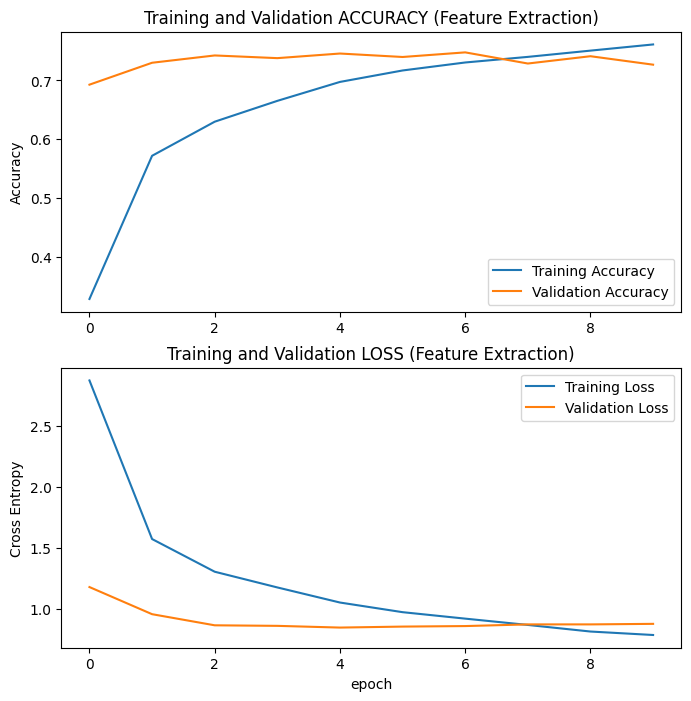

In [ ]:
## 3.5. Learning Curves (Feature Extraction)
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize = (8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label = 'Training Accuracy')
plt.plot(val_acc, label = 'Validation Accuracy')
plt.legend(loc = 'lower right')
plt.ylabel('Accuracy')
plt.title('Training and Validation ACCURACY (Feature Extraction)')

plt.subplot(2, 1, 2)
plt.plot(loss, label = 'Training Loss')
plt.plot(val_loss, label = 'Validation Loss')
plt.legend(loc = 'upper right')
plt.ylabel('Cross Entropy')
plt.title('Training and Validation LOSS (Feature Extraction)')
plt.xlabel('epoch')
plt.show()

## 4. Experiments and Tuning (Feature Extraction)
In this section, we run additional feature extraction experiments, changing one hyperparameter at a time from the baseline (Experiment 1): data augmentation, learning rate, and dropout. All decisions are based on the **validation set**; the test set is not used.

In [ ]:
## 4.1. Reusable experiment function
def RunExperiment(exp_number, use_augmentation, dropout_rate, learning_rate, epochs):
  tf.keras.utils.set_random_seed(SEED)

  # 4.1.1. Building the model
  inputs = keras.Input(shape = IMG_SHAPE)

  if use_augmentation:
    x = data_augmentation(inputs)
  else:
    x = inputs

  x = preprocess_input(x)
  x = base_model(x, training = False)
  x = layers.GlobalAveragePooling2D()(x)
  x = layers.Dropout(dropout_rate)(x)
  outputs = layers.Dense(num_classes)(x)
  exp_model = keras.Model(inputs, outputs)


  # 4.1.2. Compiling and training
  exp_model.compile(optimizer = keras.optimizers.Adam(learning_rate = learning_rate),
                    loss = keras.losses.SparseCategoricalCrossentropy(from_logits = True),
                    metrics = ['accuracy'])

  exp_history = exp_model.fit(train_dataset,
                              epochs = epochs,
                              validation_data = validation_dataset)

  # 4.1.3. Logging the experiment
  if use_augmentation:
    augmentation_text = 'with augmentation'
  else:
    augmentation_text = 'no augmentation'

  experiment_log.append({'Exp': exp_number,
                         'Parameters': 'Base = MobileNetV2, frozen base, LR = {}, batch size = {}, '
                                        'epochs = {}, dropout = {}, {}'.format(learning_rate, BATCH_SIZE,
                                                                               epochs, dropout_rate,
                                                                               augmentation_text),
                         'Train Acc.': exp_history.history['accuracy'][-1],
                         'Validation Acc.': exp_history.history['val_accuracy'][-1]})

  return exp_model, exp_history

In [ ]:
## 4.2. Running the Feature Extraction Experiments
# 4.2.1. Experiment #2: No data augmentation
exp2_model, exp2_history = RunExperiment(exp_number = 2,
                                         use_augmentation = False,
                                         dropout_rate = 0.2,
                                         learning_rate = 0.001,
                                         epochs = 10)

Epoch 1/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 56s 169ms/step - accuracy: 0.5428 - loss: 1.8815 - val_accuracy: 0.7397 - val_loss: 0.9116
Epoch 2/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 11s 48ms/step - accuracy: 0.8338 - loss: 0.5913 - val_accuracy: 0.7593 - val_loss: 0.7849
Epoch 3/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 10s 46ms/step - accuracy: 0.9034 - loss: 0.3667 - val_accuracy: 0.7684 - val_loss: 0.7576
Epoch 4/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - accuracy: 0.9462 - loss: 0.2464 - val_accuracy: 0.7697 - val_loss: 0.7515
Epoch 5/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - accuracy: 0.9651 - loss: 0.1799 - val_accuracy: 0.7678 - val_loss: 0.7406
Epoch 6/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 12s 51ms/step - accuracy: 0.9796 - loss: 0.1340 - val_accuracy: 0.7763 - val_loss: 0.7510
Epoch 7/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - accuracy: 0.9883 - loss: 0.1029 - val_accuracy: 0.7723 - val_loss: 0.7525
Epoch 8/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 11s 48ms/step - accuracy: 0.9913 - loss: 0.0825 -

In [ ]:
# 4.2.2. Experiment #3: Lower the Learning Rate
exp3_model, exp3_history = RunExperiment(exp_number = 3,
                                         use_augmentation = True,
                                         dropout_rate = 0.2,
                                         learning_rate = 0.0001,
                                         epochs = 10)

Epoch 1/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 18s 57ms/step - accuracy: 0.0479 - loss: 4.6663 - val_accuracy: 0.1748 - val_loss: 3.8051
Epoch 2/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 14s 61ms/step - accuracy: 0.1669 - loss: 3.6770 - val_accuracy: 0.3594 - val_loss: 2.9970
Epoch 3/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - accuracy: 0.2976 - loss: 3.0378 - val_accuracy: 0.4755 - val_loss: 2.4497
Epoch 4/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 21s 51ms/step - accuracy: 0.3741 - loss: 2.6191 - val_accuracy: 0.5545 - val_loss: 2.0681
Epoch 5/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - accuracy: 0.4300 - loss: 2.3231 - val_accuracy: 0.6132 - val_loss: 1.8011
Epoch 6/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 12s 52ms/step - accuracy: 0.4893 - loss: 2.1064 - val_accuracy: 0.6438 - val_loss: 1.6074
Epoch 7/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 21s 53ms/step - accuracy: 0.5100 - loss: 1.9442 - val_accuracy: 0.6725 - val_loss: 1.4645
Epoch 8/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 20s 51ms/step - accuracy: 0.5378 - loss: 1.8111 - 

In [ ]:
# 4.2.3. Experiment #4: Higher dropout
exp4_model, exp4_history = RunExperiment(exp_number = 4,
                                         use_augmentation = True,
                                         dropout_rate = 0.5,
                                         learning_rate = 0.001,
                                         epochs = 10)

Epoch 1/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 18s 58ms/step - accuracy: 0.2412 - loss: 3.3945 - val_accuracy: 0.6771 - val_loss: 1.2892
Epoch 2/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 13s 56ms/step - accuracy: 0.4784 - loss: 1.9989 - val_accuracy: 0.7175 - val_loss: 0.9844
Epoch 3/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 13s 56ms/step - accuracy: 0.5516 - loss: 1.6798 - val_accuracy: 0.7345 - val_loss: 0.8918
Epoch 4/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 12s 53ms/step - accuracy: 0.5772 - loss: 1.5361 - val_accuracy: 0.7384 - val_loss: 0.8565
Epoch 5/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 22s 61ms/step - accuracy: 0.6006 - loss: 1.4257 - val_accuracy: 0.7345 - val_loss: 0.8444
Epoch 6/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - accuracy: 0.6122 - loss: 1.3853 - val_accuracy: 0.7371 - val_loss: 0.8677
Epoch 7/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 11s 49ms/step - accuracy: 0.6323 - loss: 1.3162 - val_accuracy: 0.7371 - val_loss: 0.8465
Epoch 8/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 11s 47ms/step - accuracy: 0.6428 - loss: 1.2732 - 

In [ ]:
## 4.3. Tuning table (Feature Extraction Experiments)
results_df = pd.DataFrame(experiment_log)
results_df

# 5. Feature Extraction Results
In this section, we select the best feature extraction model based on **validation accuracy**, plot its training and validation curves, and prepare it for the fine-tuning stage.

In [ ]:
## 5.1. Selecting the best feature extraction model
best_exp = 1

if best_exp == 1:
  best_model = model
  best_history = history
elif best_exp == 2:
  best_model = exp2_model
  best_history = exp2_history
elif best_exp == 3:
  best_model = exp3_model
  best_history = exp3_history
elif best_exp == 4:
  best_model = exp4_model
  best_history = exp4_history

print('Best feature extraction model: Exp {}'.format(best_exp))
print('Validation accuracy: {:.4f}'.format(best_history.history['val_accuracy'][-1]))

Best feature extraction model: Exp 1
Validation accuracy: 0.7267


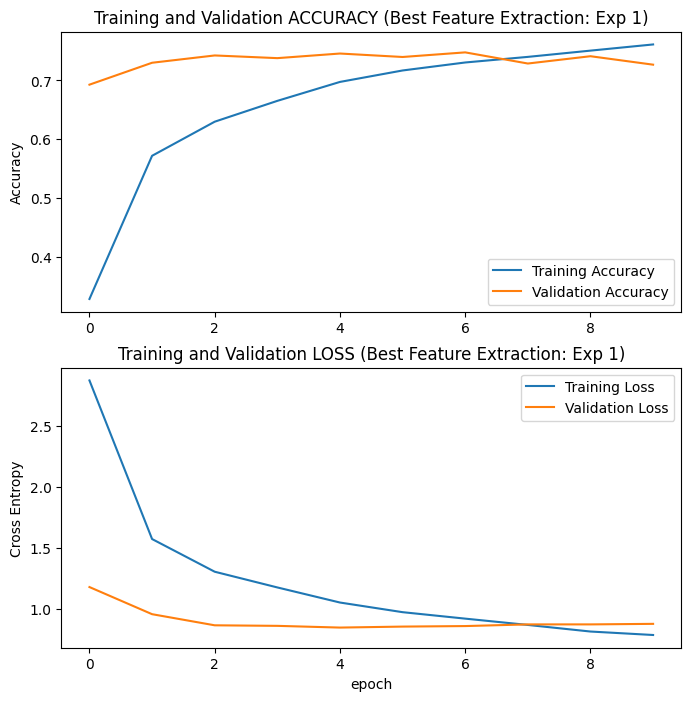

In [ ]:
## 5.2. Learning curves of the best feature extraction model
acc = best_history.history['accuracy']
val_acc = best_history.history['val_accuracy']

loss = best_history.history['loss']
val_loss = best_history.history['val_loss']

plt.figure(figsize = (8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label = 'Training Accuracy')
plt.plot(val_acc, label = 'Validation Accuracy')
plt.legend(loc = 'lower right')
plt.ylabel('Accuracy')
plt.title('Training and Validation ACCURACY (Best Feature Extraction: Exp {})'.format(best_exp))

plt.subplot(2, 1, 2)
plt.plot(loss, label = 'Training Loss')
plt.plot(val_loss, label = 'Validation Loss')
plt.legend(loc = 'upper right')
plt.ylabel('Cross Entropy')
plt.title('Training and Validation LOSS (Best Feature Extraction: Exp {})'.format(best_exp))
plt.xlabel('epoch')

plt.show()

In [ ]:
## 5.3. Preparing the best feature extraction model for Fine-Tuning
# 5.3.1. Saving the best feature extraction weights
best_model.save_weights('best_feature_extraction.weights.h5')

# 5.3.2. Values needing for fine-tuning
print('Best feature extraction model: Exp {}'.format(best_exp))
print('Number of layers in the base model: {}'.format(len(base_model.layers)))
print('Feature extraction epochs completed: {}'.format(len(best_history.epoch)))
print('Trainable variables (head only): {}'.format(len(best_model.trainable_variables)))

Best feature extraction model: Exp 1
Number of layers in the base model: 154
Feature extraction epochs completed: 10
Trainable variables (head only): 2


## 6. Fine-Tuning
In this section, we unfreeze some of the top layers of the MobileNetV2 base and continue training the best feature extraction model (Section 5) at a lower learning rate. Each fine-tuning experiment starts from the same saved feature extraction weights, and all decisions are based on the **validation set**.

In [ ]:
## 6.1. Reusable Fine-Tuning Function
def RunFineTuning(exp_number, fine_tune_at, learning_rate, fine_tune_epochs):
  tf.keras.utils.set_random_seed(SEED)

  # 6.1.1. Resetting best features extraction state
  base_model.trainable = False
  best_model.load_weights('best_feature_extraction.weights.h5')

  # 6.1.2. Un-freezing top layers of base
  base_model.trainable = True
  for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

  # 6.1.3. Compiling with a lower learning rate
  best_model.compile(optimizer = keras.optimizers.RMSprop(learning_rate = learning_rate),
                     loss = keras.losses.SparseCategoricalCrossentropy(from_logits = True),
                     metrics = ['accuracy'])

  # 6.1.4. Continuing training from where feature extraction stopped
  initial_epoch = len(best_history.epoch)
  total_epochs = initial_epoch + fine_tune_epochs

  history_fine = best_model.fit(train_dataset,
                                epochs = total_epochs,
                                initial_epoch = initial_epoch,
                                validation_data = validation_dataset)

  # 6.1.5. Logging the experiment
  num_unfrozen = len(base_model.layers) - fine_tune_at
  experiment_log.append({'Exp': exp_number,
                         'Parameters': 'Base = MobileNetV2, top {} layers unfrozen, LR = {}, batch_size = {}, '
                                        'fine-tune epochs = {}, optimizer = RMSprop'.format(num_unfrozen, learning_rate,
                                                                                            BATCH_SIZE, fine_tune_epochs),
                          'Train Acc.': history_fine.history['accuracy'][-1],
                          'Validation Acc.': history_fine.history['val_accuracy'][-1]})
  return history_fine

In [ ]:
## 6.2. Running the Fine-Tuning Experiments
# 6.2.1. Experiment #5: Un-freezing from layer 100 (top 54 layers)
history_fine_exp5 = RunFineTuning(exp_number = 5,
                                  fine_tune_at = 100,
                                  learning_rate = 0.0001,
                                  fine_tune_epochs = 10)

Epoch 11/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 28s 76ms/step - accuracy: 0.6728 - loss: 1.1131 - val_accuracy: 0.6928 - val_loss: 1.0869
Epoch 12/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 16s 71ms/step - accuracy: 0.7392 - loss: 0.8600 - val_accuracy: 0.7104 - val_loss: 1.0921
Epoch 13/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 20s 69ms/step - accuracy: 0.7795 - loss: 0.7219 - val_accuracy: 0.6817 - val_loss: 1.2190
Epoch 14/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 16s 72ms/step - accuracy: 0.8134 - loss: 0.6159 - val_accuracy: 0.6745 - val_loss: 1.2449
Epoch 15/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 20s 71ms/step - accuracy: 0.8284 - loss: 0.5470 - val_accuracy: 0.6667 - val_loss: 1.3332
Epoch 16/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 21s 71ms/step - accuracy: 0.8591 - loss: 0.4651 - val_accuracy: 0.6738 - val_loss: 1.2799
Epoch 17/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 16s 70ms/step - accuracy: 0.8683 - loss: 0.4268 - val_accuracy: 0.6719 - val_loss: 1.3260
Epoch 18/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - accuracy: 0.8931 - loss: 0

In [28]:
# 6.2.2. Experiment #6: Un-freezing the top 30 layers
history_fine_exp6 = RunFineTuning(exp_number = 6,
                                  fine_tune_at = 124,
                                  learning_rate = 0.0001,
                                  fine_tune_epochs = 10)

Epoch 11/20


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 58 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


224/224 ━━━━━━━━━━━━━━━━━━━━ 23s 68ms/step - accuracy: 0.6901 - loss: 1.0574 - val_accuracy: 0.7456 - val_loss: 0.9180
Epoch 12/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 13s 59ms/step - accuracy: 0.7480 - loss: 0.8332 - val_accuracy: 0.7286 - val_loss: 0.9634
Epoch 13/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 13s 59ms/step - accuracy: 0.7846 - loss: 0.7128 - val_accuracy: 0.7032 - val_loss: 1.0390
Epoch 14/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 13s 59ms/step - accuracy: 0.8021 - loss: 0.6302 - val_accuracy: 0.7071 - val_loss: 1.0577
Epoch 15/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 13s 59ms/step - accuracy: 0.8289 - loss: 0.5654 - val_accuracy: 0.7032 - val_loss: 1.1045
Epoch 16/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 20s 59ms/step - accuracy: 0.8526 - loss: 0.4937 - val_accuracy: 0.7052 - val_loss: 1.1509
Epoch 17/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 21s 61ms/step - accuracy: 0.8674 - loss: 0.4440 - val_accuracy: 0.6980 - val_loss: 1.1537
Epoch 18/20
224/224 ━━━━━━━━━━━━━━━━━━━━ 20s 60ms/step - accuracy: 0.8795 - loss: 0.4088 - val_

In [29]:
## 6.3. Full Tuning Table (Feature Extraction + Fine-Tuning Experiments)
results_df = pd.DataFrame(experiment_log)
results_df

,Exp,Parameters,Train Acc.,Validation Acc.
0,1,"Base = MobileNetV2, frozen base, LR = 0.001, b...",0.761006,0.726680
1,2,"Base = MobileNetV2, frozen base, LR = 0.001, b...",0.996366,0.767123
2,3,"Base = MobileNetV2, frozen base, LR = 0.0001, ...",0.575402,0.701892
3,4,"Base = MobileNetV2, frozen base, LR = 0.001, b...",0.663452,0.741031
4,5,"Base = MobileNetV2, top 54 layers unfrozen, LR...",0.909015,0.654273
5,6,"Base = MobileNetV2, top 30 layers unfrozen, LR...",0.903424,0.691455


In [30]:
## 6.4. Selecting the final model (Best fine-tuning experiment)
best_fine_exp = 6

if best_fine_exp == 5:
  best_history_fine = RunFineTuning(exp_number = 5,
                                    fine_tune_at = 100,
                                    learning_rate = 0.0001,
                                    fine_tune_epochs = 10)
  experiment_log.pop()

else:
  best_history_fine = history_fine_exp6

print('Final model: Exp {} (Feature Extraction: Exp {})'.format(best_fine_exp, best_exp))
print('Validation accuracy: {:.4f}'.format(best_history_fine.history['val_accuracy'][-1]))

Final model: Exp 6 (Feature Extraction: Exp 1)
Validation accuracy: 0.6915


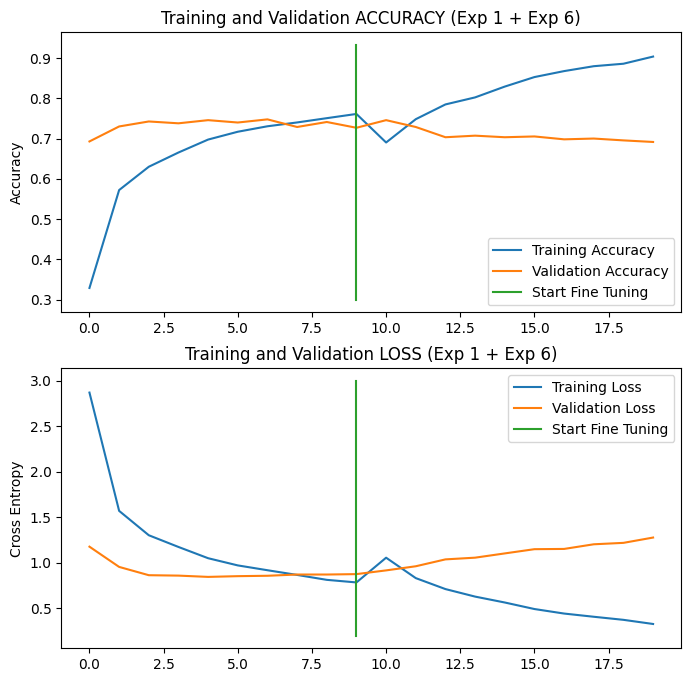

In [31]:
## 6.5. Learning curves of the final model (Feature Extraction + Fine-Tuning)
# 6.5.1. Joining the feature extraction and fine-tuning histories
acc = best_history.history['accuracy'] + best_history_fine.history['accuracy']
val_acc = best_history.history['val_accuracy'] + best_history_fine.history['val_accuracy']

loss = best_history.history['loss'] + best_history_fine.history['loss']
val_loss = best_history.history['val_loss'] + best_history_fine.history['val_loss']

initial_epochs = len(best_history.epoch)

# 6.5.2. Plotting both stages
plt.figure(figsize = (8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label = 'Training Accuracy')
plt.plot(val_acc, label = 'Validation Accuracy')
plt.plot([initial_epochs - 1, initial_epochs - 1],
         plt.ylim(), label = 'Start Fine Tuning')
plt.legend(loc = 'lower right')
plt.ylabel('Accuracy')
plt.title('Training and Validation ACCURACY (Exp {} + Exp {})'.format(best_exp, best_fine_exp))

plt.subplot(2, 1, 2)
plt.plot(loss, label = 'Training Loss')
plt.plot(val_loss, label = 'Validation Loss')
plt.plot([initial_epochs - 1, initial_epochs - 1],
         plt.ylim(), label = 'Start Fine Tuning')
plt.legend(loc = 'upper right')
plt.ylabel('Cross Entropy')
plt.title('Training and Validation LOSS (Exp {} + Exp {})'.format(best_exp, best_fine_exp))
plt.show()

## 7. Result Analysis
In this final section, we evaluate the final model (feature extraction Exp 1 + fine-tuning Exp 6) **once** on the untouched test set, and display sample predictions from the test set.

In [32]:
## 7.1. Evaluating the final model on the test set (used only once)
test_loss, test_accuracy = best_model.evaluate(test_dataset)
print('Test accuracy: {:.4f}'.format(test_accuracy))

48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.6793 - loss: 1.2234
Test accuracy: 0.6793


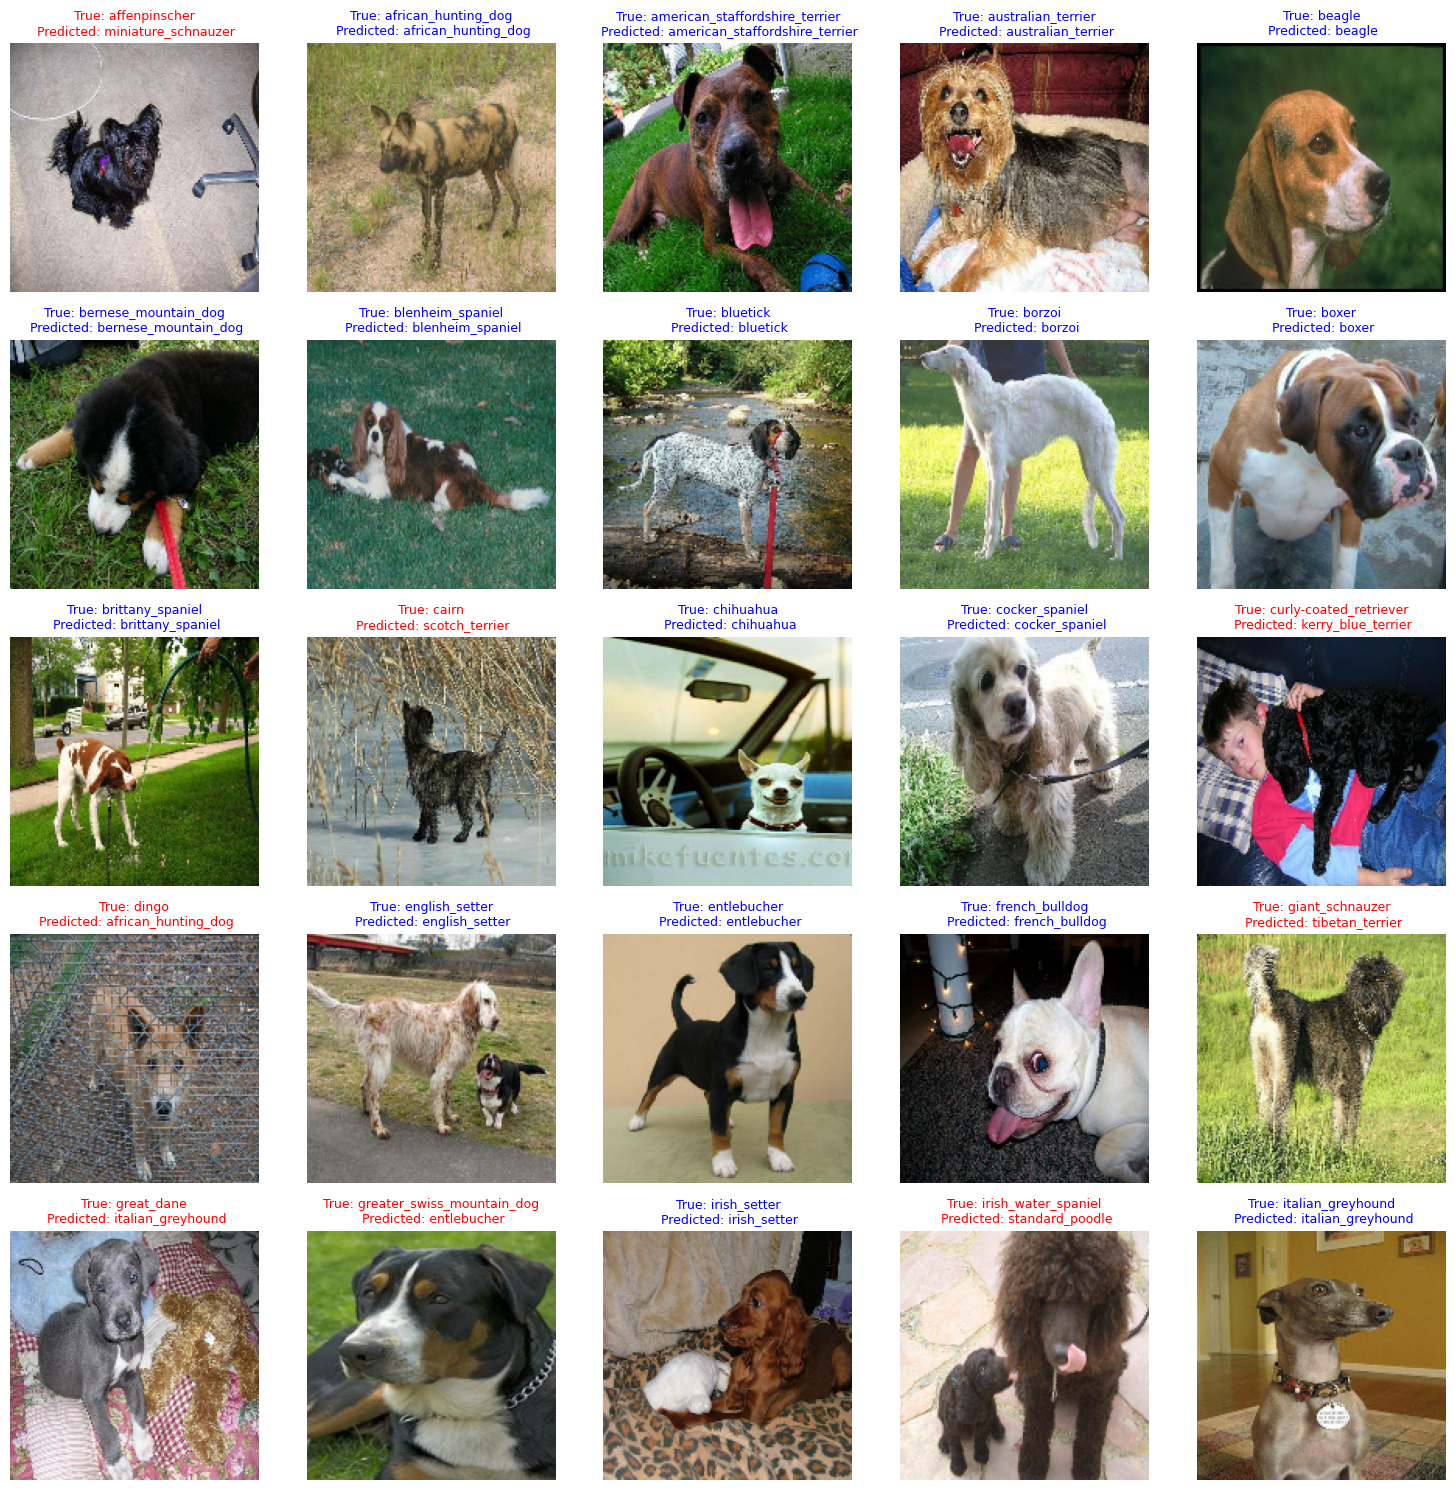

In [33]:
## 7.2. Sample predictions on the test set
plt.figure(figsize = (15, 15))

i = 0
for images, labels in test_dataset.take(25):
  # 7.2.1. Predicting the first image of each batch
  predictions = best_model.predict_on_batch(images)
  predicted_label = np.argmax(predictions[0])
  true_label = int(labels[0])

  # 7.2.2. Blue title = Correct Predictions; Red title = Incorrect Predictions
  if predicted_label == true_label:
    color = 'blue'
  else:
    color = 'red'

  plt.subplot(5, 5, i + 1)
  plt.imshow(images[0].numpy().astype('uint8'))
  plt.title('True: {}\n Predicted: {}'.format(class_names[true_label], class_names[predicted_label]),
            color = color, fontsize = 9)
  plt.axis('off')
  i = i + 1

plt.tight_layout()
plt.show()